# 04 — Baseline

Đọc feature của notebook 03 và đánh giá các quy tắc đơn giản trên V1/V2. Dữ liệu được đọc theo batch để giảm RAM.

Metric là căn của trung bình sai số bình phương log có trọng số. B0 chỉ lấy nhãn từ mốc train hợp lệ của từng fold. Validation hiện chỉ gồm cặp có lịch sử.


In [1]:
from pathlib import Path
from collections import defaultdict
from datetime import datetime, timezone
import json
import hashlib
import platform
import numpy as np
import pandas as pd
import pyarrow
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
from IPython.display import display

BATCH_SIZE = 65_536
# None: dùng mọi mốc hợp lệ. Nếu đổi cửa sổ, phải ghi nhận khi so sánh các lần chạy.
TRAIN_ORIGIN_MIN = None

def find_root():
    for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
        if (p / 'reports/03_config.json').is_file():
            return p
    raise FileNotFoundError('Không thấy reports/03_config.json. Chạy 03 trước và mở notebook trong project.')

ROOT = find_root()
REPORT = ROOT / 'reports'
TABLE = REPORT / 'table'
TABLE.mkdir(parents=True, exist_ok=True)
CONFIG_PATH = REPORT / '03_config.json'
config = json.loads(CONFIG_PATH.read_text(encoding='utf-8'))
HORIZON = int(config['horizon'])
# Chấp nhận đường dẫn tương đối được ghi từ Windows khi chạy trên Linux.
FEATURE_DIR = ROOT / config['feature_dir'].replace('\\', '/')
manifest_path = TABLE / '03_feature_manifest.csv'
manifest = pd.read_csv(manifest_path, parse_dates=['origin'])
assert not manifest.duplicated(['role', 'origin']).any(), 'Manifest trùng mốc/vai trò.'
manifest['path'] = manifest['file'].map(lambda f: FEATURE_DIR / Path(str(f)).name)
assert manifest['path'].map(Path.is_file).all(), 'Thiếu Parquet được liệt kê trong manifest.'
folds = config['folds']
assert len(folds) >= 2, 'Cần cả V1 và V2 từ notebook 03.'
print('Project:', ROOT)
print('Số file:', len(manifest), '| horizon:', HORIZON, '| batch:', BATCH_SIZE)
try:
    import psutil
    print('RAM khả dụng (GiB):', round(psutil.virtual_memory().available / 1024**3, 2))
except ImportError:
    pass


Project: D:\Machine-learning-project-Grocery-sales-forecast
Số file: 57 | horizon: 16 | batch: 65536
RAM khả dụng (GiB): 3.06


RAM khả dụng lúc bắt đầu là **1,46 GiB**. Đọc theo batch giúp chạy baseline mà không nạp toàn bộ feature vào RAM.


## 1. File đầu vào và mốc train

Chỉ dùng file trong manifest. Mốc train phải thỏa `T_train + horizon ≤ T_validation`.


In [2]:
PRED_COLS = ['dow_last', 'mean_7', 'mean_14', 'mean_28', 'dow_mean_4',
             'dow_mean_8', 'item_mean_28', 'family_store_mean_28',
             'class_mean_28', 'store_mean_28', 'pair_status']
EVAL_COLS = list(dict.fromkeys(PRED_COLS + ['y_log', 'w', 'perishable', 'h',
                  'item_family', 'origin', 'date', 'has_history']))
for r in manifest.itertuples():
    required = EVAL_COLS if r.role != 'test' else PRED_COLS + ['w', 'perishable']
    pf = pq.ParquetFile(r.path)
    absent = set(required) - set(pf.schema_arrow.names)
    assert not absent, f'{r.file}: thiếu {sorted(absent)}'
    assert pf.metadata.num_rows == int(r.rows), f'{r.file}: số dòng khác manifest'

def batches(paths, columns):
    for path in paths:
        for batch in pq.ParquetFile(path).iter_batches(batch_size=BATCH_SIZE, columns=columns):
            yield batch.to_pandas()

def split_fold(fold):
    cut = pd.Timestamp(fold['valid_origin'])
    train = manifest[(manifest.role == 'train') &
                     (manifest.origin + pd.Timedelta(days=HORIZON) <= cut)].copy()
    if TRAIN_ORIGIN_MIN is not None:
        train = train[train.origin >= pd.Timestamp(TRAIN_ORIGIN_MIN)]
    valid = manifest[(manifest.role == fold['valid_role']) & (manifest.origin == cut)].copy()
    assert len(train) and len(valid) == 1, f"Fold {fold['fold']}: thiếu train/validation"
    return cut, train, valid

fold_plans = []
for fold in folds:
    cut, tr, va = split_fold(fold)
    fold_plans.append(dict(fold=fold['fold'], valid_origin=str(cut.date()),
        train_origins=len(tr), train_rows=int(tr.rows.sum()),
        first_origin=str(tr.origin.min().date()), last_origin=str(tr.origin.max().date()),
        valid_rows=int(va.rows.sum())))
fold_plan_df = pd.DataFrame(fold_plans)
display(fold_plan_df)


,fold,valid_origin,train_origins,train_rows,first_origin,last_origin,valid_rows
0,V1_last16,2017-07-30,53,2905662,2015-06-11,2017-07-04,2786240
1,V2_seasonal,2016-08-15,26,1301649,2015-06-11,2016-07-18,1172130


V1 dùng **53 mốc, 2.905.662 dòng**; V2 dùng **26 mốc, 1.301.649 dòng**. Nhãn train không chạm vào khoảng mục tiêu của fold tương ứng.


## 2. Các quy tắc dự báo

| Tên | Cách tính |
|---|---|
| B-zero | Luôn dự báo 0 |
| B0 | Trung bình target log có trọng số trên train hợp lệ |
| B1 | Giá trị gần nhất cùng thứ đã biết tại mốc |
| B2 | Trung bình log 7, 14 hoặc 28 ngày |
| B3 | Trung bình 4 hoặc 8 lần cùng thứ |
| B4 | Cùng thứ, thiếu thì dùng item, rồi 0 |
| B5 | Cặp cũ dùng mean28; cặp mới dùng item, family–store, class, store, rồi B0 |

B0 được fit riêng từng fold nên không nhất thiết giống B0 ở 03. Nhánh cặp mới của B5 chưa có đánh giá chất lượng.


In [3]:
def fit_constant(train, cut):
    sy = sw = 0.0
    n = 0
    for d in batches(train.path, ['y_log', 'w', 'origin', 'date']):
        y = d.y_log.to_numpy(dtype=np.float64)
        w = d.w.to_numpy(dtype=np.float64)
        assert np.isfinite(y).all() and (y >= 0).all()
        assert np.isfinite(w).all() and (w > 0).all()
        assert (d.date <= cut).all(), 'Nhãn train vượt mốc validation.'
        delta = (d.date - d.origin).dt.days
        assert delta.between(1, HORIZON).all()
        sy += float(np.dot(w, y)); sw += float(w.sum()); n += len(d)
    assert sw > 0
    return sy / sw, n, sw

def fallback(d, columns, constant):
    out = np.full(len(d), np.nan, dtype=np.float64)
    for c in columns:
        a = d[c].to_numpy(dtype=np.float64)
        use = ~np.isfinite(out) & np.isfinite(a)
        out[use] = a[use]
    out[~np.isfinite(out)] = constant
    return np.maximum(out, 0)

def predict_rules(d, constant):
    hierarchy = fallback(d, ['item_mean_28', 'family_store_mean_28',
                             'class_mean_28', 'store_mean_28'], constant)
    pred = {'B-zero': np.zeros(len(d)), 'B0_constant': np.full(len(d), constant)}
    for name, col in [('B1_dow_last', 'dow_last'), ('B2a_mean7', 'mean_7'),
                      ('B2b_mean14', 'mean_14'), ('B2c_mean28', 'mean_28'),
                      ('B3a_dow4', 'dow_mean_4'), ('B3b_dow8', 'dow_mean_8')]:
        pred[name] = fallback(d, [col], 0.0)
    pred['B4_dow8_item'] = fallback(d, ['dow_mean_8', 'item_mean_28'], 0.0)
    pred['B5_mean28_hierarchy'] = np.where(
        d.pair_status.to_numpy() < 2, fallback(d, ['mean_28'], constant), hierarchy)
    return pred

# Kiểm tra nhỏ: tuyến cặp mới, thứ tự fallback và metric trên thang log.
toy = pd.DataFrame({c: [np.nan]*4 for c in PRED_COLS})
toy['pair_status'] = [0, 2, 3, 3]
toy['mean_28'] = [2., np.nan, np.nan, np.nan]
toy['item_mean_28'] = [9., 3., np.nan, np.nan]
toy['family_store_mean_28'] = [8., 8., 4., np.nan]
assert np.allclose(predict_rules(toy, 0.5)['B5_mean28_hierarchy'], [2, 3, 4, .5])
y = np.array([0., 3.]); pred = np.array([1., 5.]); w = np.array([1., 1.25])
a = np.sqrt(np.dot(w, (np.log1p(pred)-np.log1p(y))**2)/w.sum())
b = np.sqrt(np.average((np.log1p(pred)-np.log1p(y))**2, weights=w))
assert np.isclose(a, b)
print('Kiểm tra công thức và fallback: PASS')


Kiểm tra công thức và fallback: PASS


## 3. Tính điểm trên V1 và V2

Cộng sai số bình phương có trọng số của các batch, chia tổng trọng số rồi lấy căn. Không lấy trung bình đơn giản của điểm từng batch.


In [4]:
def add_stats(acc, key, y, p, w, mask):
    e = p[mask] - y[mask]
    z = acc[key]
    z[0] += int(mask.sum())
    z[1] += float(w[mask].sum())
    z[2] += float(np.dot(w[mask], e * e))

def evaluate(fold, constant, valid, cut):
    acc = defaultdict(lambda: [0, 0.0, 0.0])
    for d in batches(valid.path, EVAL_COLS):
        assert (d.origin == cut).all()
        assert ((d.date-d.origin).dt.days == d.h).all()
        assert d.h.between(1, HORIZON).all()
        assert d.pair_status.isin([0, 1, 2, 3]).all()
        assert ((d.pair_status < 2) == (d.has_history == 1)).all()
        y = d.y_log.to_numpy(dtype=np.float64)
        w = d.w.to_numpy(dtype=np.float64)
        assert np.isfinite(y).all() and (y >= 0).all()
        assert np.isfinite(w).all() and (w > 0).all()
        assert np.allclose(w, np.where(d.perishable == 1, 1.25, 1.0))
        groups = [('overall', 'all', np.ones(len(d), dtype=bool))]
        for group in ['pair_status', 'perishable', 'h', 'item_family']:
            for value in sorted(d[group].unique()):
                groups.append((group, str(int(value)), d[group].to_numpy() == value))
        for name, p in predict_rules(d, constant).items():
            assert np.isfinite(p).all() and (p >= 0).all()
            for group, value, mask in groups:
                add_stats(acc, (name, group, value), y, p, w, mask)
    rows = []
    for (name, group, value), (n, sw, sse) in acc.items():
        assert sw > 0
        rows.append(dict(fold=fold['fold'], baseline=name, group=group, value=value,
                         rows=n, weight_sum=sw, weighted_sse=sse, NWRMSLE=np.sqrt(sse/sw)))
    return pd.DataFrame(rows)

all_results, constants = [], []
for fold in folds:
    cut, tr, va = split_fold(fold)
    constant, n, sw = fit_constant(tr, cut)
    constants.append(dict(fold=fold['fold'], constant_log=constant,
                          constant_units=float(np.expm1(constant)), train_rows=n, weight_sum=sw))
    print(f"Đánh giá {fold['fold']} | train {n:,} dòng | B0 log = {constant:.5f}")
    result = evaluate(fold, constant, va, cut)
    assert (result.loc[result.group == 'overall', 'rows'] == int(va.rows.sum())).all()
    all_results.append(result)
results = pd.concat(all_results, ignore_index=True)
overall = results[results.group == 'overall'].sort_values(['fold', 'NWRMSLE']).reset_index(drop=True)
constants_df = pd.DataFrame(constants)
display(overall[['fold', 'baseline', 'rows', 'NWRMSLE']].round(6))


Đánh giá V1_last16 | train 2,905,662 dòng | B0 log = 1.12967
Đánh giá V2_seasonal | train 1,301,649 dòng | B0 log = 1.17600


,fold,baseline,rows,NWRMSLE
0,V1_last16,B2c_mean28,2786240,0.638588
1,V1_last16,B5_mean28_hierarchy,2786240,0.638588
2,V1_last16,B2b_mean14,2786240,0.646228
3,V1_last16,B2a_mean7,2786240,0.655480
4,V1_last16,B4_dow8_item,2786240,0.660580
5,V1_last16,B3b_dow8,2786240,0.660947
6,V1_last16,B3a_dow4,2786240,0.675744
7,V1_last16,B1_dow_last,2786240,0.817490
8,V1_last16,B0_constant,2786240,1.073042
9,V1_last16,B-zero,2786240,1.481961


**Trung bình 28 ngày tốt nhất ở cả hai fold.**

| Fold | NWRMSLE |
|---|---:|
| V1 | 0,638588 |
| V2 | 0,607533 |

B5 bằng B2 vì validation chưa có cặp mới. Kết quả này chưa kiểm chứng nhánh dự phòng của B5.


## 4. Điểm tổng và điểm theo nhóm

So sánh từng fold, rồi xem lỗi theo trạng thái cặp, hàng mau hỏng, horizon và family. Trung bình hai fold chỉ là số tóm tắt.


fold,V1_last16,V2_seasonal,mean_fold_score
baseline,,,
B2c_mean28,0.638588,0.607533,0.623061
B5_mean28_hierarchy,0.638588,0.607533,0.623061
B2b_mean14,0.646228,0.612034,0.629131
B2a_mean7,0.655480,0.627980,0.641730
B4_dow8_item,0.660580,0.624241,0.642410
B3b_dow8,0.660947,0.624585,0.642766
B3a_dow4,0.675744,0.639724,0.657734
B1_dow_last,0.817490,0.787044,0.802267
B0_constant,1.073042,1.059188,1.066115


,fold,baseline,NWRMSLE
0,V1_last16,B2c_mean28,0.638588
10,V2_seasonal,B2c_mean28,0.607533


Phân nhóm: pair_status


,fold,value,rows,NWRMSLE
196,V1_last16,0,2409184,0.68272
197,V1_last16,1,377056,0.19647
731,V2_seasonal,0,1063198,0.63375
732,V2_seasonal,1,108932,0.23993


Phân nhóm: perishable


,fold,value,rows,NWRMSLE
198,V1_last16,0,2154208,0.63712
199,V1_last16,1,632032,0.64258
733,V2_seasonal,0,902848,0.60579
734,V2_seasonal,1,269282,0.61219


Phân nhóm: item_family


,fold,value,rows,NWRMSLE
201,V1_last16,0,15376,0.39583
202,V1_last16,1,672,0.32608
203,V1_last16,2,12608,0.34795
204,V1_last16,3,455328,0.73060
205,V1_last16,4,416,0.10895
...,...,...,...,...
763,V2_seasonal,28,15284,0.70256
764,V2_seasonal,29,5918,0.60494
765,V2_seasonal,30,81288,0.64520
766,V2_seasonal,31,3590,0.71505


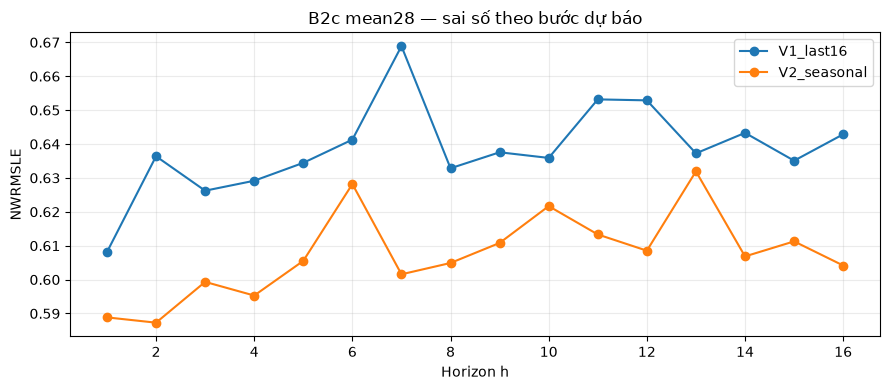

In [5]:
comparison = overall.pivot(index='baseline', columns='fold', values='NWRMSLE')
comparison['mean_fold_score'] = comparison.mean(axis=1)
comparison = comparison.sort_values('mean_fold_score')
display(comparison.round(6))
winners = overall.loc[overall.groupby('fold')['NWRMSLE'].idxmin(), ['fold','baseline','NWRMSLE']]
display(winners)
for group in ['pair_status', 'perishable', 'item_family']:
    print('Phân nhóm:', group)
    display(results[(results.group == group) & (results.baseline == 'B2c_mean28')]
            [['fold', 'value', 'rows', 'NWRMSLE']].round(5))
fig, ax = plt.subplots(figsize=(9, 4))
for fold in folds:
    r = results[(results.fold == fold['fold']) & (results.group == 'h') &
                (results.baseline == 'B2c_mean28')].copy()
    r['h'] = r.value.astype(int)
    r = r.sort_values('h')
    ax.plot(r.h, r.NWRMSLE, marker='o', label=fold['fold'])
ax.set(xlabel='Horizon h', ylabel='NWRMSLE', title='B2c mean28 — sai số theo bước dự báo')
ax.grid(alpha=.25); ax.legend(); fig.tight_layout(); plt.show()


Cặp đang bán có sai số cao hơn cặp không bán gần đây. Nhóm dễ dự báo kéo điểm tổng xuống, nên cần xem cả hai nhóm.

Hàng mau hỏng có sai số hơi cao hơn hàng thường. V2 có điểm thấp hơn V1, nhưng hai fold khác thời điểm và cơ cấu; chưa xác định nguyên nhân riêng của chênh lệch.


## 5. Cơ cấu test

Tính tỷ trọng theo số dòng và trọng số. Chỉ ước lượng lại cơ cấu cho những nhóm đã được chấm ở validation; không tự gán điểm của cặp cũ cho cặp mới.


In [6]:
test_files = manifest.loc[manifest.role == 'test', 'path'].tolist()
assert len(test_files) == 1
coverage = defaultdict(lambda: [0, 0.0])
# Fit hằng số triển khai bằng tất cả mốc train có nhãn kết thúc trước mốc test.
test_cut = pd.Timestamp(config['test_origin'])
test_tr = manifest[(manifest.role == 'train') &
    (manifest.origin + pd.Timedelta(days=HORIZON) <= test_cut)]
if TRAIN_ORIGIN_MIN is not None:
    test_tr = test_tr[test_tr.origin >= pd.Timestamp(TRAIN_ORIGIN_MIN)]
test_constant, _, _ = fit_constant(test_tr, test_cut)
for d in batches(test_files, list(dict.fromkeys(PRED_COLS + ['w', 'perishable']))):
    assert d.pair_status.isin([0, 1, 2, 3]).all()
    assert np.allclose(d.w, np.where(d.perishable == 1, 1.25, 1.0))
    p = predict_rules(d, test_constant)['B5_mean28_hierarchy']
    assert np.isfinite(p).all() and (p >= 0).all()
    for s, g in d.groupby('pair_status'):
        coverage[int(s)][0] += len(g)
        coverage[int(s)][1] += float(g.w.sum())
coverage_df = pd.DataFrame([dict(pair_status=s, rows=v[0], weight_sum=v[1])
                            for s, v in sorted(coverage.items())])
coverage_df['row_share'] = coverage_df.rows / coverage_df.rows.sum()
coverage_df['weight_share'] = coverage_df.weight_sum / coverage_df.weight_sum.sum()
display(coverage_df)
reweighted = []
for (fold, name), r in results[results.group == 'pair_status'].groupby(['fold','baseline']):
    mse = dict(zip(r.value.astype(int), r.weighted_sse / r.weight_sum))
    covered = coverage_df[coverage_df.pair_status.isin(mse)]
    share = float(covered.weight_share.sum())
    estimate = np.sqrt(sum(row.weight_share * mse[row.pair_status]
                          for row in covered.itertuples()) / share) if share else np.nan
    missing = sorted(set(coverage_df.pair_status) - set(mse))
    reweighted.append(dict(fold=fold, baseline=name, covered_test_weight_share=share,
        missing_statuses=','.join(map(str, missing)),
        estimated_score_covered_groups_only=estimate))
reweighted_df = pd.DataFrame(reweighted)
display(reweighted_df[reweighted_df.baseline == 'B2c_mean28'].round(6))
print('B5 test: dự báo log hữu hạn. Chưa đo sai số cold-start và không có nhãn test.')


,pair_status,rows,weight_sum,row_share,weight_share
0,0,2395264,2527852.0,0.710663,0.707216
1,1,264144,282220.0,0.078370,0.078957
2,2,659216,712456.0,0.195586,0.199324
3,3,51840,51840.0,0.015381,0.014503


,fold,baseline,covered_test_weight_share,missing_statuses,estimated_score_covered_groups_only
5,V1_last16,B2c_mean28,0.786173,"2,3",0.650515
15,V2_seasonal,B2c_mean28,0.786173,"2,3",0.605875


B5 test: dự báo log hữu hạn. Chưa đo sai số cold-start và không có nhãn test.


Cặp mới chiếm **21,10% dòng test**, khoảng **21,38% trọng số**. Phần này chưa được V1/V2 đánh giá.

Đổi cơ cấu các nhóm cũ theo test cho điểm ước lượng **0,650515** từ V1 và **0,605875** từ V2. Đây không phải điểm toàn bộ test; phép tính giả định sai số trong từng nhóm giữ ổn định.


## 6. Lưu kết quả

Lưu điểm tổng, điểm theo nhóm, hằng số từng fold và cơ cấu test. Notebook này không tạo submission.


In [7]:
outputs = {
    '04_fold_plan.csv': fold_plan_df,
    '04_constants.csv': constants_df,
    '04_baselines.csv': overall,
    '04_baseline_breakdown.csv': results[results.group != 'overall'],
    '04_baseline_comparison.csv': comparison.reset_index(),
    '04_test_coverage.csv': coverage_df,
    '04_test_mix_estimates.csv': reweighted_df,
}
for filename, df in outputs.items():
    df.to_csv(TABLE / filename, index=False)

def sha256(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()

report = {
    'created_at_utc': datetime.now(timezone.utc).isoformat(),
    'versions': {'python': platform.python_version(), 'numpy': np.__version__,
                 'pandas': pd.__version__, 'pyarrow': pyarrow.__version__},
    'source_config_sha256': sha256(CONFIG_PATH),
    'source_manifest_sha256': sha256(manifest_path),
    'batch_size': BATCH_SIZE, 'train_origin_min': TRAIN_ORIGIN_MIN,
    'metric': 'sqrt(sum(w * (pred_log - y_log)^2) / sum(w))',
    'folds': fold_plan_df.to_dict(orient='records'),
    'constants': constants_df.to_dict(orient='records'),
    'overall': overall.to_dict(orient='records'),
    'winners_by_fold': winners.to_dict(orient='records'),
    'test_coverage': coverage_df.to_dict(orient='records'),
    'test_prediction_finite_check': 'PASS',
    'cold_start_quality_validated': False,
    'future_promo_used': False, 'oil_used': False,
    'limits': ['V1/V2 không đo cặp mới nếu không có nhóm 2/3.',
               'Ước lượng cơ cấu test chỉ áp dụng nhóm đã đo và giả định sai số nhóm ổn định.',
               'Chưa thử bỏ qua ngày vắng, khuyến mãi tương lai hoặc giá dầu.',
               'Fingerprint cấu hình/manifest không thay cho checksum nội dung Parquet.'],
    'outputs': [str((TABLE / f).relative_to(ROOT)) for f in outputs],
}
# Chuyển NaN thành null để JSON hợp lệ nghiêm ngặt.
report = json.loads(pd.Series({'report': report}).to_json(force_ascii=False))['report']
path = REPORT / '04_baseline_report.json'
path.write_text(json.dumps(report, ensure_ascii=False, indent=2, allow_nan=False), encoding='utf-8')
print('Đã lưu:', path.relative_to(ROOT))
print('Hoàn thành baseline. Gửi notebook có output và báo cáo 04 để đối chiếu.')


Đã lưu: reports\04_baseline_report.json
Hoàn thành baseline. Gửi notebook có output và báo cáo 04 để đối chiếu.


Baseline đã chạy hết trên hai fold. Điểm B2c được dùng để so sánh với mô hình ở notebook 05. Việc B5 tạo dự báo test hữu hạn chỉ xác nhận quy tắc chạy được.


## 7. Kiểm tra kết quả

- [x] V1/V2 có kết quả, không có exception trong output.
- [x] B0 dùng mốc train hợp lệ riêng từng fold.
- [x] Có bảng điểm tổng và điểm theo nhóm.
- [x] Output xác nhận lưu báo cáo 04.
- [ ] Đánh giá chất lượng cho cặp mới.


## 8. Bước tiếp theo

Notebook 05 huấn luyện trên target log và trọng số perishable, giữ cùng quy tắc fold. So sánh riêng bản có/không có khuyến mãi tương lai và giá dầu.
